# Discovering Dark Energy — an End-to-End Machine Learning Project

This notebook contains all the code of the guide `index.html` (same folder).
Every figure of the guide is produced here and saved in `images/`.

**Data (real):** the Pantheon+ compilation of 1,701 light curves of Type Ia supernovae
(Scolnic et al. 2022; Brout et al. 2022), including the Cepheid-calibrated SH0ES hosts.

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

## Get the Data

In [2]:
import urllib.request

DOWNLOAD_ROOT = ("https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/"
                 "Pantheon%2B_Data/4_DISTANCES_AND_COVAR/")
PANTHEON_PATH = os.path.join("datasets", "pantheon_plus")

def fetch_pantheon_data(root=DOWNLOAD_ROOT, path=PANTHEON_PATH):
    os.makedirs(path, exist_ok=True)
    dat_path = os.path.join(path, "Pantheon+SH0ES.dat")
    if not os.path.exists(dat_path):
        urllib.request.urlretrieve(root + "Pantheon%2BSH0ES.dat", dat_path)
    cov_path = os.path.join(path, "Pantheon+SH0ES_STAT+SYS_cov_upper.npz")
    if not os.path.exists(cov_path):            # 33 MB of text -> 5 MB compressed
        raw = urllib.request.urlopen(root + "Pantheon%2BSH0ES_STAT%2BSYS.cov").read().decode()
        values = np.array(raw.split()[1:], dtype=float)
        n = int(np.sqrt(values.size))
        cov = values.reshape(n, n)
        cov = (cov + cov.T) / 2                 # remove rounding asymmetries
        np.savez_compressed(cov_path, upper=cov[np.triu_indices(n)].astype(np.float32))
    return dat_path, cov_path

def load_pantheon_data(path=PANTHEON_PATH):
    dat_path, cov_path = fetch_pantheon_data(path=path)
    data = pd.read_csv(dat_path, sep=r"\s+")
    upper = np.load(cov_path)["upper"].astype(float)
    n = len(data)
    cov = np.zeros((n, n))
    cov[np.triu_indices(n)] = upper
    cov = cov + cov.T - np.diag(np.diag(cov))
    return data, cov

sne, sne_cov = load_pantheon_data()
sne[["CID", "IDSURVEY", "zHD", "zHEL", "mB", "x1", "c", "m_b_corr",
     "m_b_corr_err_DIAG", "CEPH_DIST", "IS_CALIBRATOR"]].head()

,CID,IDSURVEY,zHD,zHEL,mB,x1,c,m_b_corr,m_b_corr_err_DIAG,CEPH_DIST,IS_CALIBRATOR
0,2011fe,51,0.00122,0.00082,9.58436,-0.548188,-0.107600,9.74571,1.516210,29.1770,1
1,2011fe,56,0.00122,0.00082,9.78448,-0.380481,-0.032895,9.80286,1.517230,29.1770,1
2,2012cg,51,0.00256,0.00144,11.81610,0.491960,0.100730,11.47030,0.781906,30.8433,1
3,2012cg,56,0.00256,0.00144,11.88010,0.712610,0.122470,11.49190,0.798612,30.8433,1
4,1994DRichmond,50,0.00299,0.00187,11.53340,-1.618030,-0.111684,11.52270,0.880798,-9.0000,0


In [3]:
sne[["CID", "zHD", "zHEL", "mB", "x1", "c", "m_b_corr", "m_b_corr_err_DIAG",
     "CEPH_DIST", "IS_CALIBRATOR", "HOST_LOGMASS"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 1701 entries, 0 to 1700
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CID                1701 non-null   str    
 1   zHD                1701 non-null   float64
 2   zHEL               1701 non-null   float64
 3   mB                 1701 non-null   float64
 4   x1                 1701 non-null   float64
 5   c                  1701 non-null   float64
 6   m_b_corr           1701 non-null   float64
 7   m_b_corr_err_DIAG  1701 non-null   float64
 8   CEPH_DIST          1701 non-null   float64
 9   IS_CALIBRATOR      1701 non-null   int64  
 10  HOST_LOGMASS       1701 non-null   float64
dtypes: float64(9), int64(1), str(1)
memory usage: 146.3 KB


In [4]:
print("light curves:", len(sne), "  distinct supernovae:", sne["CID"].nunique())
sne["CID"].value_counts().head()

light curves: 1701   distinct supernovae: 1543


CID
2007af     4
2006ej     4
2018gv     3
2007le     3
2017erp    3
Name: count, dtype: int64

In [5]:
sne["IDSURVEY"].value_counts().head(8)

IDSURVEY
1      321
15     269
10     203
150    179
4      160
57     105
5       89
64      58
Name: count, dtype: int64

In [6]:
sne[["zHD", "mB", "x1", "c", "m_b_corr", "m_b_corr_err_DIAG", "HOST_LOGMASS"]].describe().round(3)

,zHD,mB,x1,c,m_b_corr,m_b_corr_err_DIAG,HOST_LOGMASS
count,1701.000,1701.000,1701.000,1701.000,1701.000,1701.000,1701.000
mean,0.221,19.079,-0.076,-0.019,19.084,0.241,9.823
std,0.249,3.304,0.999,0.087,3.374,0.099,1.281
min,0.001,9.584,-2.931,-0.244,9.746,0.112,-9.000
25%,0.028,16.098,-0.740,-0.082,16.036,0.179,9.253
50%,0.164,20.052,0.049,-0.030,20.076,0.217,10.095
75%,0.329,21.762,0.683,0.035,21.825,0.279,10.693
max,2.261,26.810,2.788,0.279,26.930,1.517,12.588


Saving figure attribute_histogram_plots


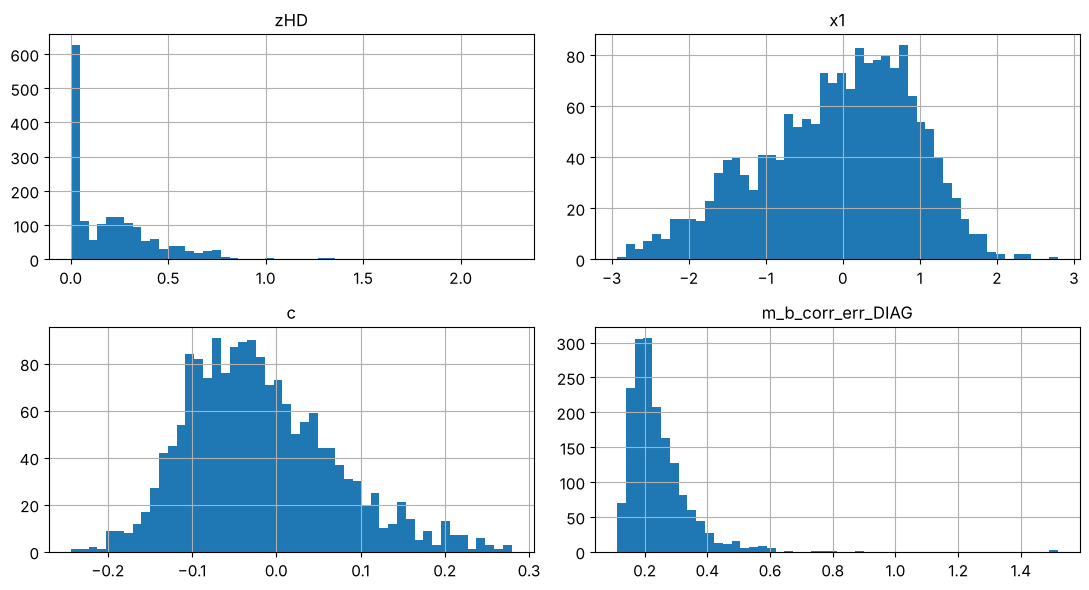

In [7]:
sne[["zHD", "x1", "c", "m_b_corr_err_DIAG"]].hist(bins=50, figsize=(11, 6))
save_fig("attribute_histogram_plots")
plt.show()

## Create a Test Set

In [8]:
sne["z_cat"] = pd.cut(sne["zHD"], bins=[0, 0.01, 0.05, 0.15, 0.4, np.inf], labels=[1, 2, 3, 4, 5])
sne["z_cat"].value_counts().sort_index()

z_cat
1    111
2    534
3    181
4    567
5    308
Name: count, dtype: int64

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

# Keep every supernova (all its light curves) on one side, and the redshift mix balanced.
calib = sne["IS_CALIBRATOR"] == 1
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(sne, sne["z_cat"], groups=sne["CID"]))
# the 77 Cepheid-calibrated light curves are precious: they all stay in the training set
test_idx = np.setdiff1d(test_idx, np.where(calib)[0])
train_idx = np.setdiff1d(np.arange(len(sne)), test_idx)
train_set, test_set = sne.iloc[train_idx], sne.iloc[test_idx]
print(len(train_set), "train,", len(test_set), "test;",
      "shared SNe:", len(set(train_set["CID"]) & set(test_set["CID"])))

1377 train, 324 test; shared SNe: 0


In [10]:
compare = pd.DataFrame({"Overall": sne["z_cat"].value_counts(normalize=True),
                        "Test": test_set["z_cat"].value_counts(normalize=True)}).sort_index()
compare["Test %error"] = 100 * compare["Test"] / compare["Overall"] - 100
compare.round(3)

,Overall,Test,Test %error
z_cat,,,
1,0.065,0.022,-66.892
2,0.314,0.324,3.230
3,0.106,0.114,7.320
4,0.333,0.352,5.556
5,0.181,0.188,3.977


## Discover and Visualize the Data to Gain Insights

Saving figure hubble_diagram_plot


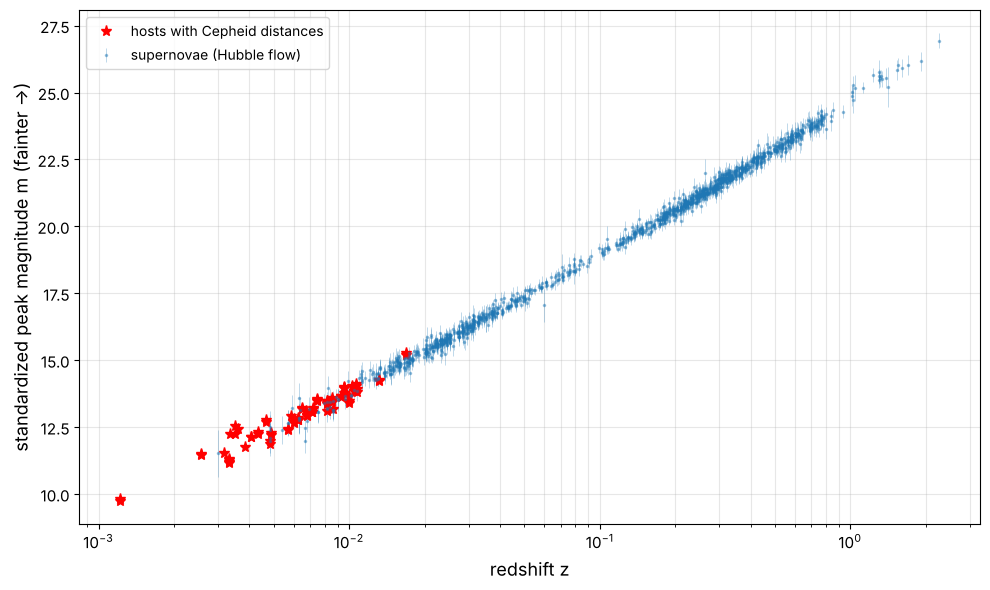

In [11]:
snes = train_set.copy()
fig, ax = plt.subplots(figsize=(10, 6))
hf = snes[snes["IS_CALIBRATOR"] == 0]
ax.errorbar(hf["zHD"], hf["m_b_corr"], yerr=hf["m_b_corr_err_DIAG"], fmt=".", ms=3,
            alpha=0.4, elinewidth=0.5, label="supernovae (Hubble flow)")
cal = snes[snes["IS_CALIBRATOR"] == 1]
ax.plot(cal["zHD"], cal["m_b_corr"], "r*", ms=8, label="hosts with Cepheid distances")
ax.set_xscale("log")
ax.set_xlabel("redshift z"); ax.set_ylabel("standardized peak magnitude m (fainter →)")
ax.grid(alpha=0.3, which="both"); ax.legend()
save_fig("hubble_diagram_plot")
plt.show()

Saving figure hubble_law_plot


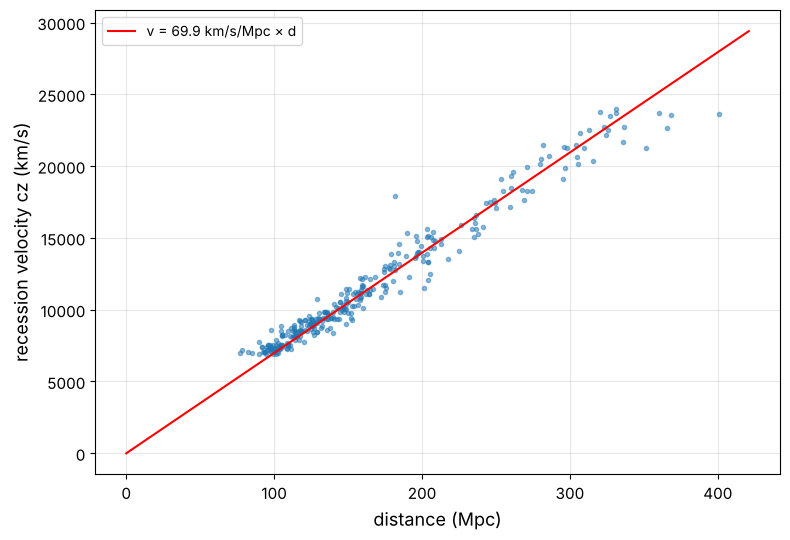

H0 ≈ 69.9 km/s/Mpc  ->  Hubble time 1/H0 = 14.0 Gyr


In [12]:
# Hubble's law at low redshift: distance from the SH0ES-calibrated distance modulus,
# velocity v = c z.   (0.023 < z < 0.08: far enough to beat local peculiar motions)
C_KMS = 299792.458
low = hf[(hf["zHD"] > 0.023) & (hf["zHD"] < 0.08)]
distance_mpc = 10 ** ((low["MU_SH0ES"] - 25) / 5)
velocity = C_KMS * low["zHD"]
from sklearn.linear_model import LinearRegression
hubble_reg = LinearRegression(fit_intercept=False).fit(distance_mpc.values.reshape(-1, 1), velocity)
H0_simple = hubble_reg.coef_[0]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(distance_mpc, velocity, ".", alpha=0.5)
dd = np.linspace(0, distance_mpc.max() * 1.05, 10)
ax.plot(dd, H0_simple * dd, "r-", label=f"v = {H0_simple:.1f} km/s/Mpc × d")
ax.set_xlabel("distance (Mpc)"); ax.set_ylabel("recession velocity cz (km/s)")
ax.grid(alpha=0.3); ax.legend()
save_fig("hubble_law_plot")
plt.show()
print(f"H0 ≈ {H0_simple:.1f} km/s/Mpc  ->  Hubble time 1/H0 = {977.8 / H0_simple:.1f} Gyr")

In [13]:
# Why are these supernovae "standard"? Look at the RAW peak magnitude mB.
# Its scatter around a smooth Hubble-flow curve correlates with light-curve width x1 and color c.
ref = hf[(hf["zHD"] > 0.023) & (hf["zHD"] < 0.15)].copy()
ref["raw_resid"] = ref["mB"] - 5 * np.log10(C_KMS * ref["zHD"] / 70 * (1 + 0.45 * ref["zHD"]))
ref[["raw_resid", "x1", "c", "HOST_LOGMASS"]].corr()["raw_resid"].round(3)

raw_resid       1.000
x1             -0.541
c               0.806
HOST_LOGMASS    0.196
Name: raw_resid, dtype: float64

Saving figure tripp_correlations_plot


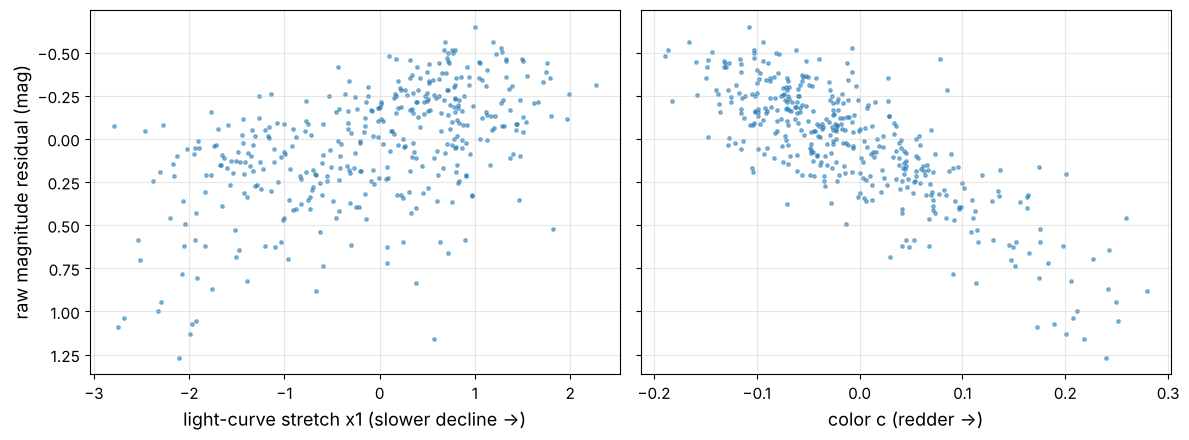

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, col, lab in [(axes[0], "x1", "light-curve stretch x1 (slower decline →)"),
                     (axes[1], "c", "color c (redder →)")]:
    ax.scatter(ref[col], ref["raw_resid"] - ref["raw_resid"].median(), s=6, alpha=0.5)
    ax.set_xlabel(lab); ax.grid(alpha=0.3)
axes[0].set_ylabel("raw magnitude residual (mag)")
axes[0].invert_yaxis()
save_fig("tripp_correlations_plot")
plt.show()

In [15]:
# Attribute combination: m_std = mB + alpha * x1 - beta * c  (the "Tripp formula")
X_tripp = ref[["x1", "c"]].values
tripp_reg = LinearRegression().fit(X_tripp, ref["raw_resid"])
alpha, beta = -tripp_reg.coef_[0], tripp_reg.coef_[1]
ref["std_resid"] = ref["raw_resid"] + alpha * ref["x1"] - beta * ref["c"]
print(f"alpha = {alpha:.3f}, beta = {beta:.2f}")
print(f"scatter before: {ref['raw_resid'].std():.3f} mag   after: {ref['std_resid'].std():.3f} mag")

alpha = 0.124, beta = 2.75
scatter before: 0.342 mag   after: 0.153 mag


## Prepare the Data for Machine Learning Algorithms

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

KIND_HUBBLE_FLOW, KIND_CALIBRATOR = 0, 1

class SupernovaFeatures(BaseEstimator, TransformerMixin):
    """DataFrame -> [zHD, zHEL, kind, Cepheid distance modulus, error, row index].
    z_min drops nearby supernovae whose redshifts are dominated by peculiar velocities."""
    def __init__(self, z_min=0.01):
        self.z_min = z_min
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def keep(self, X):
        return (X["IS_CALIBRATOR"] == 1) | (X["zHD"] > self.z_min)
    def transform(self, X):
        X = X[self.keep(X)]
        kind = np.where(X["IS_CALIBRATOR"] == 1, KIND_CALIBRATOR, KIND_HUBBLE_FLOW)
        return np.c_[X["zHD"], X["zHEL"], kind, X["CEPH_DIST"], X["m_b_corr_err_DIAG"],
                     X.index.values]

prep = SupernovaFeatures()
X_train = prep.fit_transform(train_set)
y_train = train_set.loc[prep.keep(train_set), "m_b_corr"].values
X_train.shape, y_train.shape

((1340, 6), (1340,))

## Select and Train a Model

In [17]:
from scipy.integrate import cumulative_trapezoid

def comoving_distance(z, H0, Om, OL, w=-1.0):
    """Line-of-sight comoving distance (Mpc) for a universe with matter, curvature
    and dark energy with equation of state w (w = -1: cosmological constant)."""
    zz = np.linspace(0, max(np.max(z), 2.5), 3000)
    Ok = 1 - Om - OL
    E = np.sqrt(Om * (1 + zz) ** 3 + Ok * (1 + zz) ** 2 + OL * (1 + zz) ** (3 * (1 + w)))
    chi = np.interp(z, zz, cumulative_trapezoid(1 / E, zz, initial=0))
    if Ok > 1e-8:
        chi = np.sinh(np.sqrt(Ok) * chi) / np.sqrt(Ok)
    elif Ok < -1e-8:
        chi = np.sin(np.sqrt(-Ok) * chi) / np.sqrt(-Ok)
    return C_KMS / H0 * chi

def distance_modulus(z, zhel, H0, Om, OL, w=-1.0):
    d_L = (1 + zhel) * comoving_distance(z, H0, Om, OL, w)       # luminosity distance
    return 5 * np.log10(d_L) + 25                                 # Mpc -> 10 pc

distance_modulus(np.array([0.1, 0.5, 1.0]), np.array([0.1, 0.5, 1.0]), 70, 0.3, 0.7)

array([38.31520441, 42.2611853 , 44.1002376 ])

In [18]:
from scipy.optimize import least_squares
from sklearn.base import RegressorMixin

MODELS = {   # name: (free cosmological parameters, function -> (Om, OL, w))
    "empty":      ([], lambda q: (0.0, 0.0, -1.0)),
    "matter only": ([], lambda q: (1.0, 0.0, -1.0)),
    "flat LCDM":  (["Om"], lambda q: (q[0], 1 - q[0], -1.0)),
    "LCDM":       (["Om", "OL"], lambda q: (q[0], q[1], -1.0)),
    "flat wCDM":  (["Om", "w"], lambda q: (q[0], 1 - q[0], q[1])),
}
START = {"Om": 0.3, "OL": 0.7, "w": -1.0}

class CosmologyRegressor(BaseEstimator, RegressorMixin):
    """Predicts standardized supernova magnitudes. Two kinds of rows:
    calibrators:  m = M + mu_Cepheid            (rung 2 of the distance ladder)
    Hubble flow:  m = M + mu_model(z; H0, ...)  (rung 3)
    so M (the true brightness) and H0 are learned together with the cosmology."""
    def __init__(self, model="flat LCDM", cov=None):
        self.model = model
        self.cov = cov                    # full covariance matrix (optional)
    def _predict(self, p, X):
        names, to_params = MODELS[self.model]
        M, H0 = p[0], p[1]
        Om, OL, w = to_params(p[2:])
        out = M + X[:, 3]                                   # calibrators
        hf = X[:, 2] == KIND_HUBBLE_FLOW
        out[hf] = M + distance_modulus(X[hf, 0], X[hf, 1], H0, Om, OL, w)
        return out
    def fit(self, X, y):
        names, _ = MODELS[self.model]
        p0 = np.r_[-19.3, 70.0, [START[n] for n in names]]
        if self.cov is None:
            whiten = lambda r: r / X[:, 4]
        else:                     # generalized least squares: whiten with Cholesky factor
            rows = X[:, 5].astype(int)
            L = np.linalg.cholesky(self.cov[np.ix_(rows, rows)])
            from scipy.linalg import solve_triangular
            whiten = lambda r: solve_triangular(L, r, lower=True)
        res = least_squares(lambda p: whiten(y - self._predict(p, X)), p0, x_scale="jac")
        self.result_ = res
        self.params_ = dict(zip(["M", "H0"] + names, res.x))
        self.chi2_ = 2 * res.cost
        return self
    def predict(self, X):
        return self._predict(np.array(list(self.params_.values())), X)
    def score(self, X, y):
        return -np.mean(((y - self.predict(X)) / X[:, 4]) ** 2)    # minus chi2 per SN

In [19]:
fits = {}
for name in MODELS:
    fits[name] = CosmologyRegressor(name).fit(X_train, y_train)
summary = pd.DataFrame({name: {**{k: round(v, 3) for k, v in reg.params_.items()},
                               "chi2": round(reg.chi2_, 1)} for name, reg in fits.items()}).T
summary

,M,H0,chi2,Om,OL,w
empty,-19.252,71.348,593.0,NaN,NaN,NaN
matter only,-19.252,67.471,1108.2,NaN,NaN,NaN
flat LCDM,-19.252,73.195,562.7,0.342,NaN,NaN
LCDM,-19.252,73.040,562.1,0.284,0.578,NaN
flat wCDM,-19.252,73.022,562.2,0.272,NaN,-0.845


In [20]:
best_chi2 = summary["chi2"].min()
(summary["chi2"] - best_chi2).sort_values()

LCDM             0.0
flat wCDM        0.1
flat LCDM        0.6
empty           30.9
matter only    546.1
Name: chi2, dtype: float64

Saving figure residuals_vs_empty_universe_plot


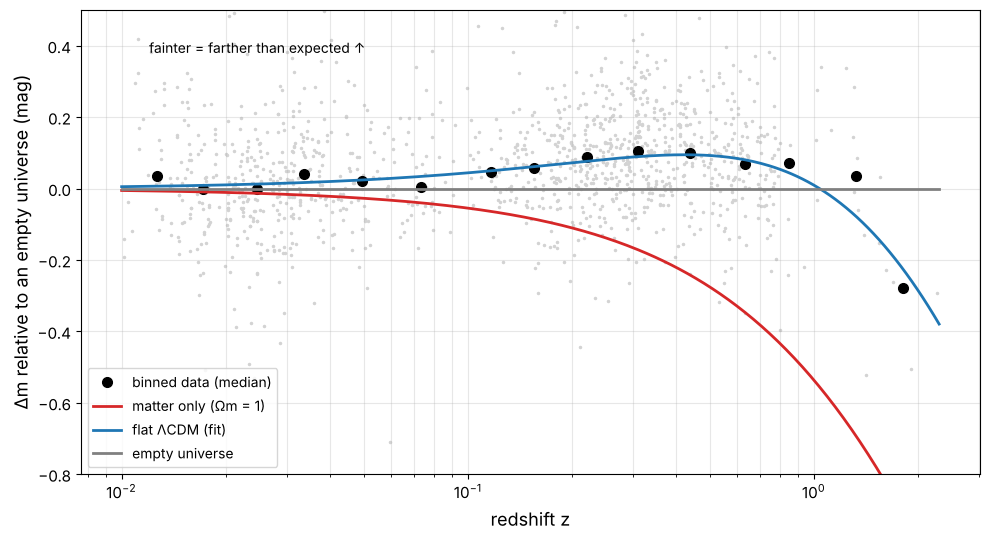

In [21]:
# The classic 1998 plot: magnitudes relative to an empty (coasting) universe.
# All curves share the same M and H0 (from the flat LCDM fit), so they agree at low z.
z_plot = np.logspace(-2, np.log10(2.3), 300)
p_ref = fits["flat LCDM"].params_
M_ref, H0_ref = p_ref["M"], p_ref["H0"]
mu_empty = distance_modulus(z_plot, z_plot, H0_ref, 0, 0)
hf_rows = X_train[:, 2] == KIND_HUBBLE_FLOW
z_hf = X_train[hf_rows, 0]
resid_empty = y_train[hf_rows] - M_ref - distance_modulus(z_hf, X_train[hf_rows, 1], H0_ref, 0, 0)
bins = np.logspace(-2, np.log10(2.3), 16)
which = np.digitize(z_hf, bins)
zb = [np.median(z_hf[which == k]) for k in range(1, len(bins)) if (which == k).sum() > 3]
rb = [np.median(resid_empty[which == k]) for k in range(1, len(bins)) if (which == k).sum() > 3]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(z_hf, resid_empty, ".", color="lightgray", ms=3, zorder=0)
ax.plot(zb, rb, "ko", ms=7, label="binned data (median)")
for (Om, OL), color, label in [((1.0, 0.0), "tab:red", "matter only (Ωm = 1)"),
                               ((p_ref["Om"], 1 - p_ref["Om"]), "tab:blue", "flat ΛCDM (fit)"),
                               ((0.0, 0.0), "gray", "empty universe")]:
    ax.plot(z_plot, distance_modulus(z_plot, z_plot, H0_ref, Om, OL) - mu_empty, color=color, lw=2, label=label)
ax.set_xscale("log"); ax.set_ylim(-0.8, 0.5)
ax.text(0.012, 0.38, "fainter = farther than expected ↑", fontsize=10)
ax.set_xlabel("redshift z"); ax.set_ylabel("Δm relative to an empty universe (mag)")
ax.grid(alpha=0.3, which="both"); ax.legend(loc="lower left")
save_fig("residuals_vs_empty_universe_plot")
plt.show()

In [22]:
# A model-agnostic check: Taylor-expand the distance in z (cosmography).
# d_L = (c z / H0) [1 + (1 - q0) z / 2 - (1 - q0 - 3 q0² + j0) z² / 6]   -> linear in features
low_z = (X_train[:, 2] == KIND_HUBBLE_FLOW) & (X_train[:, 0] < 0.4)
z_l, m_l = X_train[low_z, 0], y_train[low_z]
p_flat = fits["flat LCDM"].params_
x_dl = 10 ** ((m_l - p_flat["M"] - 25) / 5) * p_flat["H0"] / (C_KMS * z_l) - 1   # = (1-q0)z/2 + ...
features = np.c_[z_l / 2, -z_l ** 2 / 6]
cosmo_reg = LinearRegression(fit_intercept=False).fit(features, x_dl,
                                                       sample_weight=1 / X_train[low_z, 4] ** 2)
q0 = 1 - cosmo_reg.coef_[0]
print(f"deceleration parameter q0 = {q0:.2f}   ({'ACCELERATING' if q0 < 0 else 'decelerating'})")

deceleration parameter q0 = -0.50   (ACCELERATING)


In [23]:
from sklearn.model_selection import GroupKFold

groups = train_set.loc[prep.keep(train_set), "CID"].values
def display_scores(scores):
    print("Scores:", np.round(scores, 3), " Mean:", round(scores.mean(), 3),
          " Std:", round(scores.std(), 3))

cv_scores = {}
for name in MODELS:
    scores = []
    for tr, va in GroupKFold(5).split(X_train, y_train, groups):
        reg = CosmologyRegressor(name).fit(X_train[tr], y_train[tr])
        scores.append(-reg.score(X_train[va], y_train[va]))
    cv_scores[name] = np.array(scores)
    print(f"--- {name} ---"); display_scores(cv_scores[name])

--- empty ---
Scores: [0.408 0.491 0.465 0.406 0.454]  Mean: 0.445  Std: 0.033
--- matter only ---
Scores: [0.713 0.874 0.859 0.88  0.821]  Mean: 0.83  Std: 0.062
--- flat LCDM ---
Scores: [0.383 0.487 0.436 0.384 0.425]  Mean: 0.423  Std: 0.038
--- LCDM ---
Scores: [0.385 0.485 0.436 0.383 0.425]  Mean: 0.423  Std: 0.038
--- flat wCDM ---
Scores: [0.385 0.486 0.436 0.383 0.425]  Mean: 0.423  Std: 0.038


In [24]:
# A generic ML regressor on log(z) as a baseline (calibrators can't be used: no z needed)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score
hf_train = X_train[:, 2] == KIND_HUBBLE_FLOW
knn = KNeighborsRegressor(n_neighbors=25)
scores = cross_val_score(knn, np.log10(X_train[hf_train, :1]), y_train[hf_train],
                         groups=groups[hf_train], cv=GroupKFold(5), scoring="neg_mean_squared_error")
print(f"k-NN RMSE: {np.sqrt(-scores.mean()):.3f} mag (vs flat LCDM: "
      f"{np.sqrt(np.mean((y_train - fits['flat LCDM'].predict(X_train))[hf_train] ** 2)):.3f} mag)")
far = np.log10(np.array([[3.0], [5.0]]))
print("k-NN prediction at z = 3 and 5:", knn.fit(np.log10(X_train[hf_train, :1]),
      y_train[hf_train]).predict(far).round(2), " ΛCDM:",
      (p_flat["M"] + distance_modulus(np.array([3.0, 5.0]), np.array([3.0, 5.0]), p_flat["H0"],
                                       p_flat["Om"], 1 - p_flat["Om"])).round(2))

k-NN RMSE: 0.186 mag (vs flat LCDM: 0.152 mag)
k-NN prediction at z = 3 and 5: [25.35 25.35]  ΛCDM: [27.59 28.9 ]


## Fine-Tune Your Model

In [25]:
# Scan the (Omega_m, Omega_Lambda) plane: for each pair, fit only M and H0
Om_grid = np.linspace(0.0, 1.0, 41)
OL_grid = np.linspace(0.0, 1.4, 57)
chi2_map = np.zeros((len(OL_grid), len(Om_grid)))
hf_rows = X_train[:, 2] == KIND_HUBBLE_FLOW
for i, OL in enumerate(OL_grid):
    for j, Om in enumerate(Om_grid):
        def r(p):
            pred = p[0] + X_train[:, 3]
            pred[hf_rows] = p[0] + distance_modulus(X_train[hf_rows, 0], X_train[hf_rows, 1], p[1], Om, OL)
            return (y_train - pred) / X_train[:, 4]
        if OL > 0 and Om < 0.2 and OL > 1.0 + 1.5 * Om:      # 'bouncing' universes: no Big Bang
            chi2_map[i, j] = np.nan; continue
        chi2_map[i, j] = 2 * least_squares(r, [-19.25, 73.0]).cost
dchi2 = chi2_map - np.nanmin(chi2_map)
best_i, best_j = np.unravel_index(np.nanargmin(chi2_map), chi2_map.shape)
print(f"best grid point: Om = {Om_grid[best_j]:.3f}, OL = {OL_grid[best_i]:.3f}")

best grid point: Om = 0.275, OL = 0.575


Saving figure omega_m_omega_lambda_plot


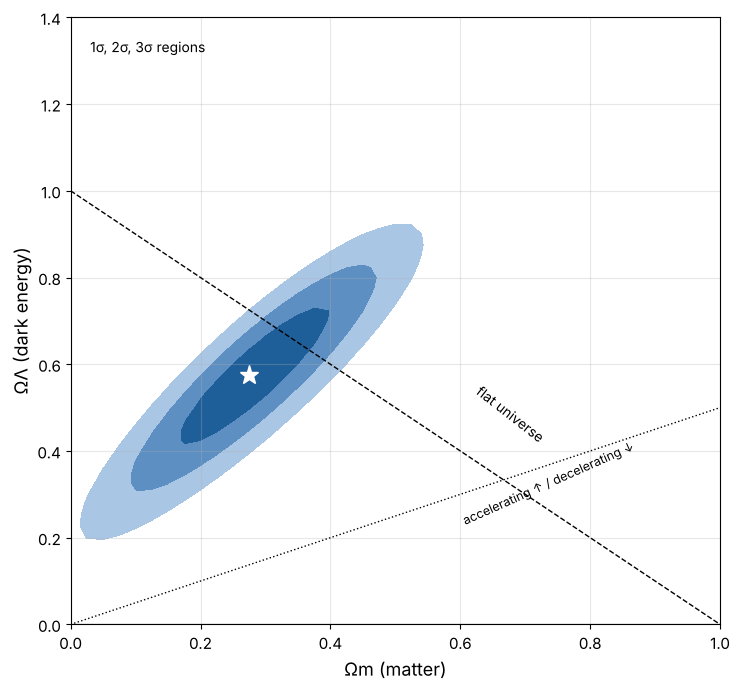

a universe without dark energy is excluded at ≈ 6 sigma (diagonal errors)


In [26]:
fig, ax = plt.subplots(figsize=(7.5, 7))
cs = ax.contourf(Om_grid, OL_grid, dchi2, levels=[0, 2.30, 6.18, 11.83], colors=["#1f5f99", "#5d8fc2", "#a9c6e4"])
ax.plot(Om_grid[best_j], OL_grid[best_i], "w*", ms=14)
ax.plot([0, 1], [1, 0], "k--", lw=1); ax.text(0.62, 0.42, "flat universe", rotation=-38)
ax.plot([0, 1], [0, 0.5], "k:", lw=1); ax.text(0.6, 0.23, "accelerating ↑ / decelerating ↓", rotation=24, fontsize=9)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Ωm (matter)"); ax.set_ylabel("ΩΛ (dark energy)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.4); ax.grid(alpha=0.3)
ax.text(0.03, 1.32, "1σ, 2σ, 3σ regions", fontsize=10)
save_fig("omega_m_omega_lambda_plot")
plt.show()
sig_no_lambda = np.sqrt(np.nanmin(dchi2[OL_grid == 0]))
print(f"a universe without dark energy is excluded at ≈ {sig_no_lambda:.0f} sigma (diagonal errors)")

In [27]:
# Supernovae share calibration and survey errors: they are NOT independent.
# Refit with the full statistical + systematic covariance matrix (generalized least squares).
final_fits = {name: CosmologyRegressor(name, cov=sne_cov).fit(X_train, y_train)
              for name in ["flat LCDM", "LCDM", "flat wCDM"]}
pd.DataFrame({n: {k: round(v, 3) for k, v in r.params_.items()} for n, r in final_fits.items()}).T

,M,H0,Om,OL,w
flat LCDM,-19.244,73.671,0.323,NaN,NaN
LCDM,-19.243,73.558,0.280,0.611,NaN
flat wCDM,-19.243,73.535,0.271,NaN,-0.876


In [28]:
# Uncertainty of H0 and Om: bootstrap over SUPERNOVAE (all light curves of a SN together)
rng = np.random.RandomState(42)
cids = np.unique(groups)
by_cid = {c: np.where(groups == c)[0] for c in cids}
boot = []
for k in range(200):
    pick = rng.choice(cids, len(cids), replace=True)
    idx = np.concatenate([by_cid[c] for c in pick])
    reg = CosmologyRegressor("flat LCDM").fit(X_train[idx], y_train[idx])
    boot.append([reg.params_["H0"], reg.params_["Om"], reg.params_["M"]])
boot = pd.DataFrame(boot, columns=["H0", "Om", "M"])
boot.describe().loc[["mean", "std"]].round(4)

,H0,Om,M
mean,73.1591,0.3397,-19.2539
std,0.9345,0.0135,0.0277


Saving figure residual_analysis_plot


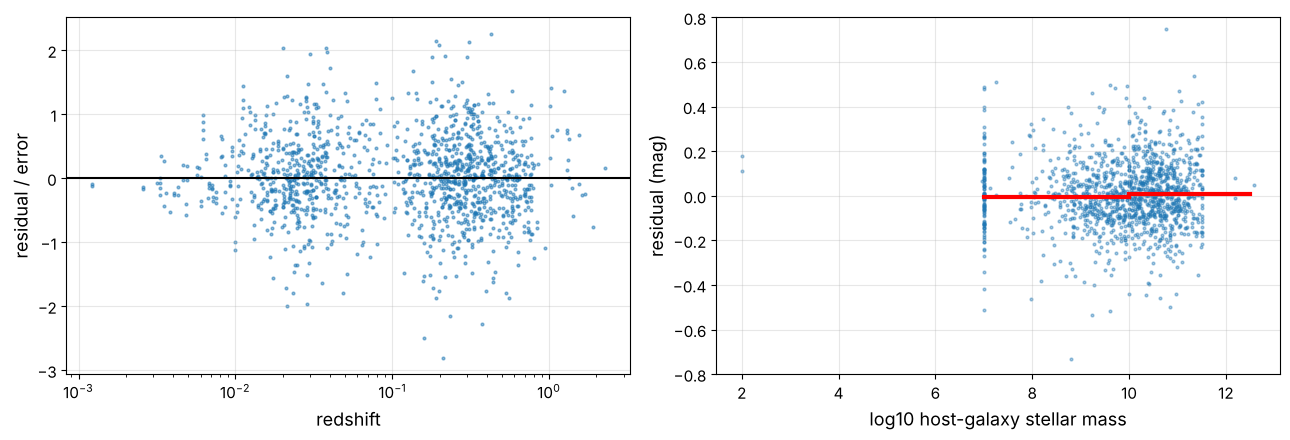

median residual: low-mass hosts -0.006, high-mass hosts +0.008 mag


In [29]:
final = final_fits["flat LCDM"]
pulls = (y_train - final.predict(X_train)) / X_train[:, 4]
host_mass = train_set.loc[prep.keep(train_set), "HOST_LOGMASS"].values
ok = host_mass > 0
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(X_train[:, 0], pulls, s=4, alpha=0.5); axes[0].set_xscale("log")
axes[0].axhline(0, color="k"); axes[0].set_xlabel("redshift"); axes[0].set_ylabel("residual / error")
resid_mag = (y_train - final.predict(X_train))[ok]
axes[1].scatter(host_mass[ok], resid_mag, s=4, alpha=0.4)
for lo, hi in [(7, 10), (10, 12.5)]:
    sel = (host_mass[ok] >= lo) & (host_mass[ok] < hi)
    axes[1].plot([lo, hi], [np.median(resid_mag[sel])] * 2, "r-", lw=3)
axes[1].set_xlabel("log10 host-galaxy stellar mass"); axes[1].set_ylabel("residual (mag)")
axes[1].set_ylim(-0.8, 0.8)
for ax in axes: ax.grid(alpha=0.3)
save_fig("residual_analysis_plot")
plt.show()
lo_m = np.median(resid_mag[host_mass[ok] < 10]); hi_m = np.median(resid_mag[host_mass[ok] >= 10])
print(f"median residual: low-mass hosts {lo_m:+.3f}, high-mass hosts {hi_m:+.3f} mag")

## Evaluate Your System on the Test Set

In [30]:
X_test = prep.transform(test_set)
y_test = test_set.loc[prep.keep(test_set), "m_b_corr"].values
for name in ["matter only", "empty", "flat LCDM"]:
    print(f"{name:12s} test chi2 per SN = {-fits[name].score(X_test, y_test):.3f}")
test_resid = y_test - final.predict(X_test)
print(f"flat LCDM (GLS fit) test RMS = {np.sqrt(np.mean(test_resid ** 2)):.3f} mag")

matter only  test chi2 per SN = 0.812
empty        test chi2 per SN = 0.472
flat LCDM    test chi2 per SN = 0.455
flat LCDM (GLS fit) test RMS = 0.158 mag


## Present Your Solution

In [31]:
from scipy.integrate import quad
p = final.params_
H0, Om = p["H0"], p["Om"]
Hz = lambda z: H0 * np.sqrt(Om * (1 + z) ** 3 + (1 - Om))
age = quad(lambda z: 1 / ((1 + z) * Hz(z)), 0, np.inf)[0] * 977.8      # Gyr
q0_model = Om / 2 - (1 - Om)
z_acc = (2 * (1 - Om) / Om) ** (1 / 3) - 1
print(f"H0 = {H0:.2f} km/s/Mpc,  Omega_m = {Om:.3f},  Omega_Lambda = {1 - Om:.3f}")
print(f"age of the Universe       = {age:.2f} Gyr")
print(f"deceleration parameter q0 = {q0_model:.2f}")
print(f"acceleration began at z   = {z_acc:.2f}  ({quad(lambda z: 1 / ((1 + z) * Hz(z)), z_acc, np.inf)[0] * 977.8:.1f} Gyr after the Big Bang)")
dm = distance_modulus(np.array([0.5]), np.array([0.5]), H0, Om, 1 - Om)[0] - \
     distance_modulus(np.array([0.5]), np.array([0.5]), H0, 1, 0)[0]
print(f"at z = 0.5 supernovae are {dm:.2f} mag ({100 * (10 ** (dm / 2.5) - 1):.0f}%) fainter than in a matter-only universe")

H0 = 73.67 km/s/Mpc,  Omega_m = 0.323,  Omega_Lambda = 0.677
age of the Universe       = 12.53 Gyr
deceleration parameter q0 = -0.52
acceleration began at z   = 0.61  (7.1 Gyr after the Big Bang)
at z = 0.5 supernovae are 0.38 mag (42%) fainter than in a matter-only universe


## Launch, Monitor, and Maintain Your System

In [32]:
planck_H0, planck_err = 67.4, 0.5          # Planck 2018 (cosmic microwave background + LCDM)
our_err = boot["H0"].std()
print(f"our H0 = {H0:.2f} ± {our_err:.2f} (statistical only)   Planck: {planck_H0} ± {planck_err}")
print(f"difference = {(H0 - planck_H0) / np.hypot(our_err, planck_err):.1f} sigma (statistical errors only)")

our H0 = 73.67 ± 0.93 (statistical only)   Planck: 67.4 ± 0.5
difference = 5.9 sigma (statistical errors only)


In [33]:
# Monitoring the model class: let dark energy evolve, w(a) = w0 + wa (1 - a)
def mu_w0wa(z, zhel, H0, Om, w0, wa):
    zz = np.linspace(0, max(np.max(z), 2.5), 3000)
    de = (1 + zz) ** (3 * (1 + w0 + wa)) * np.exp(-3 * wa * zz / (1 + zz))
    E = np.sqrt(Om * (1 + zz) ** 3 + (1 - Om) * de)
    chi = np.interp(z, zz, cumulative_trapezoid(1 / E, zz, initial=0))
    return 5 * np.log10((1 + zhel) * C_KMS / H0 * chi) + 25
hf = X_train[:, 2] == KIND_HUBBLE_FLOW
rows = X_train[:, 5].astype(int)
from scipy.linalg import solve_triangular
L = np.linalg.cholesky(sne_cov[np.ix_(rows, rows)])
def r_w0wa(p):
    pred = p[0] + X_train[:, 3]
    pred[hf] = p[0] + mu_w0wa(X_train[hf, 0], X_train[hf, 1], p[1], p[2], p[3], p[4])
    return solve_triangular(L, y_train - pred, lower=True)
res = least_squares(r_w0wa, [-19.25, 73, 0.3, -1.0, 0.0], x_scale="jac",
                    bounds=([-20, 50, 0.01, -3, -5], [-18, 100, 0.99, 1, 3]))
cov_p = np.linalg.inv(res.jac.T @ res.jac)
print(f"w0 = {res.x[3]:.2f} ± {np.sqrt(cov_p[3, 3]):.2f},  wa = {res.x[4]:.2f} ± {np.sqrt(cov_p[4, 4]):.2f}"
      f"   (cosmological constant: w0 = -1, wa = 0)")
print(f"Δchi2 vs flat LCDM (GLS) = {2 * res.cost - final.chi2_:.2f} for 2 extra parameters")

w0 = -0.76 ± 2.28,  wa = 0.60 ± 4.99   (cosmological constant: w0 = -1, wa = 0)
Δchi2 vs flat LCDM (GLS) = -0.62 for 2 extra parameters


In [34]:
import json
os.makedirs("animations", exist_ok=True)
zb_all = np.logspace(np.log10(0.011), np.log10(2.3), 22)
w_all = np.digitize(X_train[hf, 0], zb_all)
binned = []
for k in range(1, len(zb_all)):
    s = w_all == k
    if s.sum() >= 3:
        binned.append([float(np.median(X_train[hf][s, 0])),
                       float(np.average(y_train[hf][s] - p["M"], weights=1 / X_train[hf][s, 4] ** 2)),
                       float(1 / np.sqrt(np.sum(1 / X_train[hf][s, 4] ** 2)))])
anim = {"H0": float(H0), "Om": float(Om), "M": float(p["M"]), "binned": binned,
        "points": np.c_[X_train[hf, 0], y_train[hf] - p["M"]][::3].round(4).tolist(),
        "grid": {"Om": Om_grid.round(3).tolist(), "OL": OL_grid.round(3).tolist(),
                 "dchi2": np.where(np.isnan(dchi2), -1, dchi2).round(2).tolist()}}
with open(os.path.join("animations", "fitted_parameters.json"), "w") as f:
    json.dump(anim, f)
print(len(binned), "bins exported")

20 bins exported
